In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# 设置 pandas 显示
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei'] 
plt.rcParams['axes.unicode_minus'] = False

# 确保输出文件夹存在，用于保存图表
os.makedirs('../outputs', exist_ok=True)

# 🌟 定义通用的一键清洗函数（按列位置切片，彻底避免表头文字差异）
def clean_financial_data(file_path):
    df = pd.read_excel(file_path)
    # 只提取第 0, 2, 3 列（即项目、2025、2024），无视表头
    df = df.iloc[:, [0, 2, 3]].copy()
    df.columns = ['Item', 'Amount_2025', 'Amount_2024']
    # 清理项目名中的空格、冒号和换行
    df['Item'] = df['Item'].astype(str).str.strip().str.replace('：', '').str.replace(':', '').str.replace('\n', '')
    # 删除项目名称为空的行
    df = df.dropna(subset=['Item'])
    return df

【合并资产负债表】
2025年资产负债率：58.27% (2024年为 60.80%)


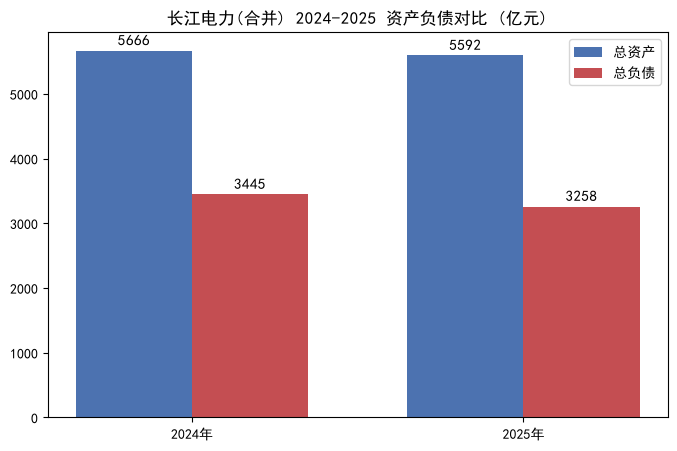

In [37]:
# 1. 读取并清洗资产负债表
df_balance = clean_financial_data('../data/consolidated/balance_sheet.xlsx')

# 2. 提取数据 (⚠️ 注意：这里换成了 == 绝对精准匹配，防止抓到“流动负债合计”)
asset_25 = float(df_balance[df_balance['Item'] == '资产总计'].iloc[0]['Amount_2025'])
asset_24 = float(df_balance[df_balance['Item'] == '资产总计'].iloc[0]['Amount_2024'])
liab_25 = float(df_balance[df_balance['Item'] == '负债合计'].iloc[0]['Amount_2025'])
liab_24 = float(df_balance[df_balance['Item'] == '负债合计'].iloc[0]['Amount_2024'])

# 3. 计算并打印
ratio_25 = (liab_25 / asset_25) * 100
ratio_24 = (liab_24 / asset_24) * 100

print(f"【合并资产负债表】")
print(f"2025年资产负债率：{ratio_25:.2f}% (2024年为 {ratio_24:.2f}%)")

# 4. 画图并保存
plt.figure(figsize=(8, 5))
x = np.arange(2)
width = 0.35

# 把数据转换为亿元，方便在柱子上显示
assets_yi = [asset_24/1e8, asset_25/1e8]
liabs_yi = [liab_24/1e8, liab_25/1e8]

# 画柱子
bars1 = plt.bar(x - width/2, assets_yi, width, label='总资产', color='#4C72B0')
bars2 = plt.bar(x + width/2, liabs_yi, width, label='总负债', color='#C44E52')

# 🌟 核心新增：在柱子上写具体数值
for bar in bars1:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 50, f'{yval:.0f}', ha='center', va='bottom', fontsize=11)

for bar in bars2:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 50, f'{yval:.0f}', ha='center', va='bottom', fontsize=11)

plt.title('长江电力(合并) 2024-2025 资产负债对比 (亿元)')
plt.xticks(x, ['2024年', '2025年'])
plt.legend()
plt.savefig('../outputs/consolidated_balance_chart.png') # 保存到 outputs 文件夹
plt.show()

In [38]:
df_income = clean_financial_data('../data/consolidated/income_statement.xlsx')

rev_25 = float(df_income[df_income['Item'].str.contains('营业总收入')].iloc[0]['Amount_2025'])
rev_24 = float(df_income[df_income['Item'].str.contains('营业总收入')].iloc[0]['Amount_2024'])
profit_25 = float(df_income[df_income['Item'].str.contains('净利润')].iloc[0]['Amount_2025'])
profit_24 = float(df_income[df_income['Item'].str.contains('净利润')].iloc[0]['Amount_2024'])

print(f"【合并利润表】")
print(f"2025年营业总收入：{rev_25/1e8:.2f} 亿元")
print(f"2025年净利润：{profit_25/1e8:.2f} 亿元")
print(f"2025年净利率：{(profit_25/rev_25)*100:.2f}% (2024年为 {(profit_24/rev_24)*100:.2f}%)")

【合并利润表】
2025年营业总收入：862.42 亿元
2025年净利润：349.49 亿元
2025年净利率：40.52% (2024年为 38.97%)


In [39]:
df_cf = clean_financial_data('../data/consolidated/cash_flow.xlsx')

ocf_25 = float(df_cf[df_cf['Item'].str.contains('经营活动产生的现金流量净额')].iloc[0]['Amount_2025'])
capex_25 = float(df_cf[df_cf['Item'].str.contains('购建固定资产')].iloc[0]['Amount_2025'])
fcf_25 = ocf_25 - capex_25

print(f"【合并现金流量表】")
print(f"2025年经营现金流净额：{ocf_25/1e8:.2f} 亿元")
print(f"2025年资本开支(CapEx)：{capex_25/1e8:.2f} 亿元")
print(f"2025年自由现金流(FCF)：{fcf_25/1e8:.2f} 亿元")
print(f"2025年净现比：{ocf_25/profit_25:.2f}")

【合并现金流量表】
2025年经营现金流净额：605.63 亿元
2025年资本开支(CapEx)：184.88 亿元
2025年自由现金流(FCF)：420.74 亿元
2025年净现比：1.73
